In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

RANDOM_STATE = 42

In [ ]:
#Mounting google drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
file_path = "/content/drive/Shareddrives/ai/features_engineered_data.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape: (9901, 22)


,Customer ID,Subscription Length (Months),Customer Satisfaction Score (1-10),Daily Watch Time (Hours),Engagement Rate (1-10),Device Used Most Often,Genre Preference,Region,Payment History (On-Time/Delayed),Subscription Plan,...,Age,Monthly Income ($),Promotional Offers Used,Number of Profiles Created,Churn_Numeric,Low_Watch_Time,Low_Satisfaction,Low_Engagement,Payment_Risk,High_Support_Usage
0,CUST109419,62.0,8.0,1.45,2.0,Smartphone,comedy,north-america,delayed,standard,...,41.0,22495.0,0.0,2.0,0,0,0,1,1,0
1,CUST108768,54.0,7.0,5.10,7.0,Laptop,thriller,north-america,on-time,basic,...,30.0,70506.0,2.0,1.0,0,0,0,0,0,0
2,CUST107656,25.0,6.0,3.78,6.0,Tablet,sci-fi,north-america,on-time,standard,...,24.0,67448.0,2.0,4.0,0,0,0,0,0,0
3,CUST100416,31.0,8.0,2.28,3.0,Tablet,drama,latin-america,on-time,basic,...,48.0,65227.5,0.0,3.0,0,0,0,1,0,0
4,CUST103710,19.0,5.0,2.84,5.0,Smartphone,drama,asia-pacific,on-time,basic,...,41.0,31250.0,0.0,1.0,0,0,0,0,0,0


In [ ]:
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Columns:
['Customer ID', 'Subscription Length (Months)', 'Customer Satisfaction Score (1-10)', 'Daily Watch Time (Hours)', 'Engagement Rate (1-10)', 'Device Used Most Often', 'Genre Preference', 'Region', 'Payment History (On-Time/Delayed)', 'Subscription Plan', 'Churn Status (Yes/No)', 'Support Queries Logged', 'Age', 'Monthly Income ($)', 'Promotional Offers Used', 'Number of Profiles Created', 'Churn_Numeric', 'Low_Watch_Time', 'Low_Satisfaction', 'Low_Engagement', 'Payment_Risk', 'High_Support_Usage']

Data types:
Customer ID                            object
Subscription Length (Months)          float64
Customer Satisfaction Score (1-10)    float64
Daily Watch Time (Hours)              float64
Engagement Rate (1-10)                float64
Device Used Most Often                 object
Genre Preference                       object
Region                                 object
Payment History (On-Time/Delayed)      object
Subscription Plan                      object
Churn Status (Ye

In [ ]:
target_column = "Churn_Numeric"
columns_to_exclude = ["Customer ID", "Churn Status (Yes/No)", target_column]

if target_column not in df.columns:
    raise ValueError(f"Target column '{target_column}' was not found. Check the input CSV.")

# Convert target to numeric and validate its values.
y = pd.to_numeric(df[target_column], errors="coerce")

if y.isna().any():
    raise ValueError("Churn_Numeric contains missing or non-numeric values. Fix the target before training.")

if not set(y.unique()).issubset({0, 1}):
    raise ValueError(f"Churn_Numeric must contain only 0 and 1. Found: {sorted(y.unique())}")

# Remove rows with invalid target only if there are any; normally validation above stops first.
X = df.drop(columns=columns_to_exclude, errors="ignore").copy()

# Ensure the income feature is retained when it exists.
if "Monthly Income ($)" in X.columns:
    print("Monthly Income ($) is INCLUDED in model features.")
else:
    print("WARNING: Monthly Income ($) is not present in the dataset.")

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\\nTarget distribution:")
print(y.value_counts().rename(index={0: "No Churn", 1: "Churn"}))
print("\\nTarget proportions:")
print(y.value_counts(normalize=True).rename(index={0: "No Churn", 1: "Churn"}).round(3))

Monthly Income ($) is INCLUDED in model features.
X shape: (9901, 19)
y shape: (9901,)
\nTarget distribution:
Churn_Numeric
No Churn    7432
Churn       2469
Name: count, dtype: int64
\nTarget proportions:
Churn_Numeric
No Churn    0.751
Churn       0.249
Name: proportion, dtype: float64


In [ ]:
#checking categorial and numerical data
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical features:")
print(numeric_features)
print("\\nCategorical features:")
print(categorical_features)

if "Monthly Income ($)" in X.columns:
    assert "Monthly Income ($)" in numeric_features, "Monthly Income ($) should be treated as a numeric feature."

Numerical features:
['Subscription Length (Months)', 'Customer Satisfaction Score (1-10)', 'Daily Watch Time (Hours)', 'Engagement Rate (1-10)', 'Support Queries Logged', 'Age', 'Monthly Income ($)', 'Promotional Offers Used', 'Number of Profiles Created', 'Low_Watch_Time', 'Low_Satisfaction', 'Low_Engagement', 'Payment_Risk', 'High_Support_Usage']
\nCategorical features:
['Device Used Most Often', 'Genre Preference', 'Region', 'Payment History (On-Time/Delayed)', 'Subscription Plan']


In [ ]:
# Making train and test distribution
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\\nTesting target distribution:")
print(y_test.value_counts(normalize=True).sort_index())

Training samples: 7920
Testing samples: 1981
\nTraining target distribution:
Churn_Numeric
0    0.750631
1    0.249369
Name: proportion, dtype: float64
\nTesting target distribution:
Churn_Numeric
0    0.750631
1    0.249369
Name: proportion, dtype: float64


In [ ]:
#Making pipeline for training
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

In [ ]:
#Making Logistic regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)
y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression trained.")

Logistic Regression trained.


In [ ]:
#Evaluating
print("Logistic Regression")
print("--------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_lr, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_lr, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))

print("\\nClassification Report:")
print(classification_report(
    y_test, y_pred_lr,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0
))

Logistic Regression
--------------------
Accuracy: 0.6446239273094396
Precision: 0.3806818181818182
Recall: 0.6781376518218624
F1 Score: 0.487627365356623
ROC-AUC: 0.730319993247824
\nClassification Report:
              precision    recall  f1-score   support

    No Churn       0.86      0.63      0.73      1487
       Churn       0.38      0.68      0.49       494

    accuracy                           0.64      1981
   macro avg       0.62      0.66      0.61      1981
weighted avg       0.74      0.64      0.67      1981



In [ ]:
#Making Random Forest Pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)
y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest trained.")

Random Forest trained.


In [ ]:
print("Random Forest")
print("-------------")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_rf, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_rf, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\\nClassification Report:")
print(classification_report(
    y_test, y_pred_rf,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0
))

Random Forest
-------------
Accuracy: 0.7617364967188289
Precision: 0.6037735849056604
Recall: 0.12955465587044535
F1 Score: 0.21333333333333335
ROC-AUC: 0.7033167342338049
\nClassification Report:
              precision    recall  f1-score   support

    No Churn       0.77      0.97      0.86      1487
       Churn       0.60      0.13      0.21       494

    accuracy                           0.76      1981
   macro avg       0.69      0.55      0.54      1981
weighted avg       0.73      0.76      0.70      1981



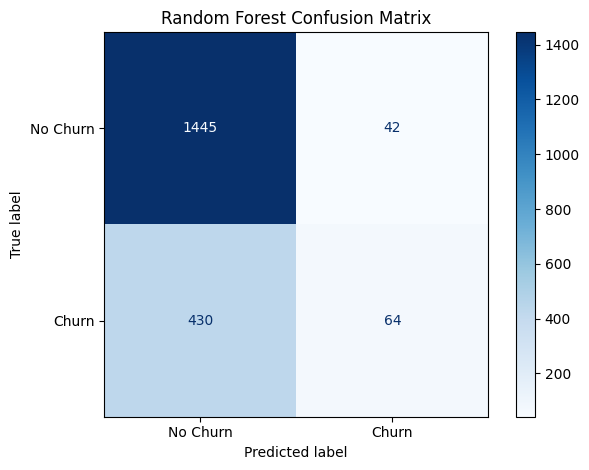

Confusion matrix:
[[1445   42]
 [ 430   64]]


In [ ]:
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No Churn", "Churn"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm_rf)

In [ ]:
#Making Gradient Boosting Pipline
gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE
    ))
])

gradient_boosting_model.fit(X_train, y_train)
y_pred_gb = gradient_boosting_model.predict(X_test)
y_prob_gb = gradient_boosting_model.predict_proba(X_test)[:, 1]

print("Gradient Boosting trained.")

Gradient Boosting trained.


In [ ]:
print("Gradient Boosting")
print("-----------------")
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_gb, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_gb, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_gb))

print("\\nClassification Report:")
print(classification_report(
    y_test, y_pred_gb,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0
))

Gradient Boosting
-----------------
Accuracy: 0.7703180212014135
Precision: 0.6258064516129033
Recall: 0.19635627530364372
F1 Score: 0.29892141756548535
ROC-AUC: 0.717089267579481
\nClassification Report:
              precision    recall  f1-score   support

    No Churn       0.78      0.96      0.86      1487
       Churn       0.63      0.20      0.30       494

    accuracy                           0.77      1981
   macro avg       0.70      0.58      0.58      1981
weighted avg       0.74      0.77      0.72      1981



In [ ]:
#Comparing all methods
model_results = []

for model_name, y_pred, y_prob in [
    ("Logistic Regression", y_pred_lr, y_prob_lr),
    ("Random Forest", y_pred_rf, y_prob_rf),
    ("Gradient Boosting", y_pred_gb, y_prob_gb)
]:
    model_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(model_results).sort_values(
    by="ROC-AUC", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.6446,0.3807,0.6781,0.4876,0.7303
1,Gradient Boosting,0.7703,0.6258,0.1964,0.2989,0.7171
2,Random Forest,0.7617,0.6038,0.1296,0.2133,0.7033


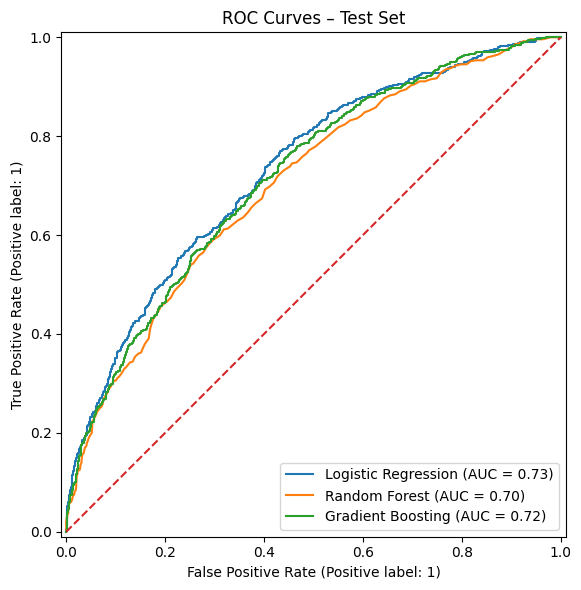

In [ ]:
plt.figure(figsize=(8, 6))

for model_name, model, y_prob in [
    ("Logistic Regression", logistic_model, y_prob_lr),
    ("Random Forest", random_forest_model, y_prob_rf),
    ("Gradient Boosting", gradient_boosting_model, y_prob_gb)
]:
    RocCurveDisplay.from_predictions(
        y_test, y_prob, name=model_name, ax=plt.gca()
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.title("ROC Curves – Test Set")
plt.tight_layout()
plt.show()

In [ ]:
#Applying Stratified K-Folds for all methods
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

models_for_cv = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

cv_results = []

for model_name, model in models_for_cv.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )
    cv_results.append({
        "Model": model_name,
        "CV ROC-AUC Mean": scores.mean(),
        "CV ROC-AUC Std": scores.std(),
        "Fold Scores": np.round(scores, 4).tolist()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    by="CV ROC-AUC Mean", ascending=False
).reset_index(drop=True)

display(cv_results_df)

,Model,CV ROC-AUC Mean,CV ROC-AUC Std,Fold Scores
0,Logistic Regression,0.733162,0.016243,"[0.7071, 0.7493, 0.7367, 0.7231, 0.7495]"
1,Gradient Boosting,0.722626,0.010752,"[0.7107, 0.7311, 0.7181, 0.7141, 0.7391]"
2,Random Forest,0.720399,0.013878,"[0.6987, 0.7308, 0.713, 0.7209, 0.7385]"


In [ ]:
best_model_name = cv_results_df.loc[0, "Model"]
print("Best model based on mean cross-validation ROC-AUC:", best_model_name)

best_models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}
best_model = best_models[best_model_name]
print("The selected model has been trained on the training split.")

Best model based on mean cross-validation ROC-AUC: Logistic Regression
The selected model has been trained on the training split.


Best model based on mean cross-validation ROC-AUC:
**Logistic Regression**

In [ ]:
#Compairing Performance of all methods
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

models = {
    "Logistic Regression": (y_pred_lr, y_prob_lr),
    "Random Forest": (y_pred_rf, y_prob_rf),
    "Gradient Boosting": (y_pred_gb, y_prob_gb)
}

results = []

for name, (pred, prob) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))


                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  Logistic Regression     0.645      0.381   0.678     0.488    0.730
1        Random Forest     0.762      0.604   0.130     0.213    0.703
2    Gradient Boosting     0.770      0.626   0.196     0.299    0.717


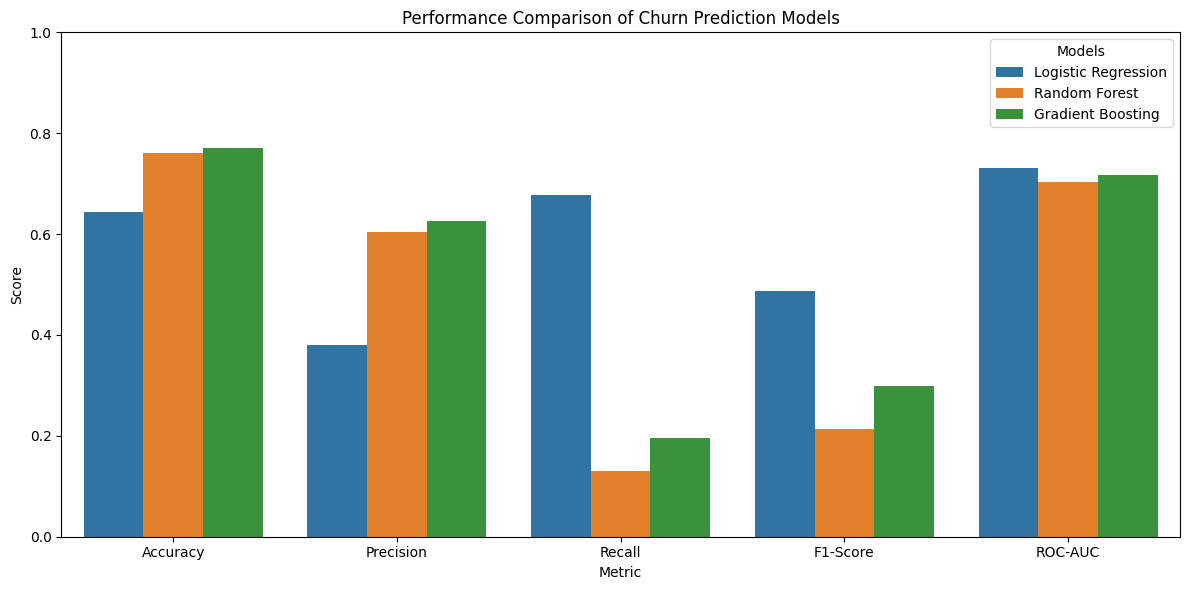

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Performance Comparison of Churn Prediction Models")
plt.ylim(0, 1)
plt.legend(title="Models")
plt.tight_layout()
plt.show()


In [ ]:
#Cross-Validating
from sklearn.model_selection import cross_val_score

cv_models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

cv_results = []

for name, model in cv_models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="roc_auc",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean ROC-AUC": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

print(cv_df.round(4))


                 Model  Mean ROC-AUC  Standard Deviation
0  Logistic Regression        0.7304              0.0155
1        Random Forest        0.7198              0.0134
2    Gradient Boosting        0.7233              0.0164


In [ ]:

best_model_name = cv_df.loc[
    cv_df["Mean ROC-AUC"].idxmax(), "Model"
]

best_model = cv_models[best_model_name]

print("Best Model:", best_model_name)

print(
    "Cross-validation ROC-AUC:",
    round(cv_df["Mean ROC-AUC"].max(), 4)
)


Best Model: Logistic Regression
Cross-validation ROC-AUC: 0.7304


Best Model on the bases of Cross-Validation : **Logistic Regression**


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

best_model.fit(X_train, y_train)

y_pred_final = best_model.predict(X_test)
y_prob_final = best_model.predict_proba(X_test)[:, 1]

print("Final Model:", best_model_name)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_final,
    target_names=["No Churn", "Churn"]
))

print("Final ROC-AUC:",
      round(roc_auc_score(y_test, y_prob_final), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))


Final Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.86      0.63      0.73      1487
       Churn       0.38      0.68      0.49       494

    accuracy                           0.64      1981
   macro avg       0.62      0.66      0.61      1981
weighted avg       0.74      0.64      0.67      1981

Final ROC-AUC: 0.7303

Confusion Matrix:
[[942 545]
 [159 335]]


In [ ]:
#Making Validation Set
from sklearn.model_selection import train_test_split
from sklearn.base import clone

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

lr_tuning_model = clone(logistic_model)

lr_tuning_model.fit(X_fit, y_fit)

print("Training samples:", len(X_fit))
print("Validation samples:", len(X_val))


Training samples: 6336
Validation samples: 1584


Checking for Threshold

In [ ]:
from sklearn.metrics import precision_recall_curve
import numpy as np

y_val_prob = lr_tuning_model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("Best Threshold:", round(best_threshold, 3))
print("Validation Precision:", round(precision[best_index], 3))
print("Validation Recall:", round(recall[best_index], 3))
print("Validation F1-score:", round(f1_scores[best_index], 3))


Best Threshold: 0.471
Validation Precision: 0.388
Validation Recall: 0.754
Validation F1-score: 0.512


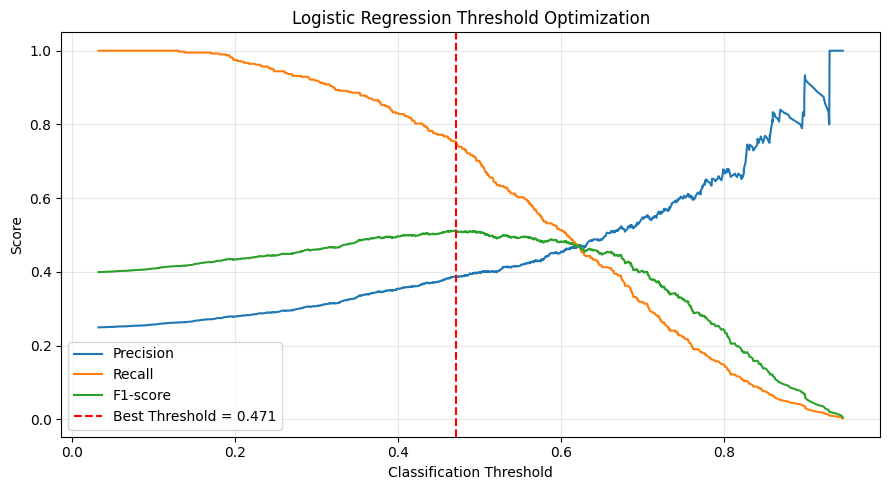

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.plot(thresholds, f1_scores, label="F1-score")

plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Best Threshold = {best_threshold:.3f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Logistic Regression Threshold Optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Tuning the Logistic Regression for better results

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Retrain using the complete training dataset
final_lr_model = clone(logistic_model)
final_lr_model.fit(X_train, y_train)

# Predict test probabilities
y_test_prob = final_lr_model.predict_proba(X_test)[:, 1]

# Apply the selected validation threshold
y_test_tuned = (
    y_test_prob >= best_threshold
).astype(int)

print("Tuned Logistic Regression Results")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_tuned,
    target_names=["No Churn", "Churn"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_tuned))

print("\nROC-AUC:",
      round(roc_auc_score(y_test, y_test_prob), 4))


Tuned Logistic Regression Results

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.87      0.60      0.71      1487
       Churn       0.37      0.73      0.49       494

    accuracy                           0.63      1981
   macro avg       0.62      0.66      0.60      1981
weighted avg       0.75      0.63      0.65      1981


Confusion Matrix:
[[888 599]
 [135 359]]

ROC-AUC: 0.7303


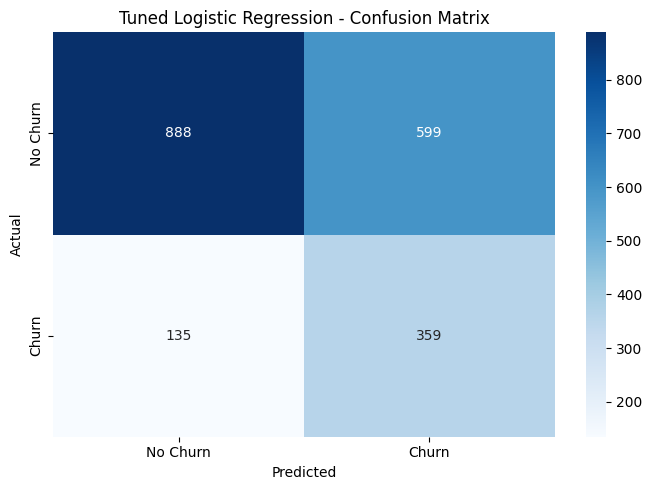

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_tuned = confusion_matrix(y_test, y_test_tuned)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned Logistic Regression - Confusion Matrix")

plt.tight_layout()
plt.show()


In [ ]:

import joblib

final_model_package = {
    "model": final_lr_model,
    "threshold": 0.465,
    "model_name": "Logistic Regression"
}

joblib.dump(
    final_model_package,
    "/content/drive/Shareddrives/ai/netflix_churn_final_model.pkl"
)

print("Final model package saved!")


Final model package saved!
